# Лабораторная работа №4
Многослойный персептрон $p$–$N$–$1$ для прогнозирования временного ряда.

Вариант 7: $x_k = 3\cdot\cos(0.22\,k) + 1.5\cdot\sin(0.55\,k)$, $p=8$, $N=6$.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

np.random.seed(42)


class DenseLayer:
    def __init__(self, units=1, activation='relu'):
        self.units = units
        self.activation = activation.lower()
        self.w = None
        self.b = None
        self.input = None
        self.z = None

    def init_weights(self, fan_in):
        self.w = np.random.uniform(-0.5, 0.5, (fan_in, self.units))
        if self.activation in ['relu', 'leaky_relu']:
            self.b = np.random.uniform(0.05, 0.25, self.units)
        else:
            self.b = np.zeros(self.units)

    def forward(self, x):
        if self.w is None:
            self.init_weights(x.shape[-1])

        self.z = x @ self.w + self.b

        if self.activation == 'relu':
            return np.maximum(0, self.z)

        elif self.activation == 'leaky_relu':
            return np.maximum(0.01 * self.z, self.z)

        elif self.activation == 'sigmoid':
            return 1 / (1 + np.exp(-np.clip(self.z, -500, 500)))

        elif self.activation == 'tanh':
            return np.tanh(self.z)

        elif self.activation == 'softmax':
            exp_z = np.exp(self.z - np.max(self.z, axis=1, keepdims=True))
            return exp_z / np.sum(exp_z, axis=1, keepdims=True)

        elif self.activation == 'linear':
            return self.z

        else:
            raise ValueError(f"Неизвестная активация: {self.activation}")

    def derivative(self, a):
        if self.activation == 'relu':
            return (self.z > 0).astype(float)

        elif self.activation == 'leaky_relu':
            return (self.z > 0).astype(float) + 0.01 * (self.z <= 0).astype(float)

        elif self.activation == 'sigmoid':
            return a * (1 - a)

        elif self.activation == 'tanh':
            return 1 - a**2

        elif self.activation == 'linear':
            return np.ones_like(a)

        elif self.activation == 'softmax':
            return np.ones_like(a)

        return np.ones_like(a)


class Input:
    def __init__(self, shape=None):
        self.shape = shape

    def forward(self, x):
        if self.shape is not None:
            expected = self.shape if isinstance(self.shape, tuple) else (self.shape,)
            if x.shape[1:] != expected:
                x = x.reshape((x.shape[0],) + expected)
        return x


class Dropout:
    def __init__(self, rate=0.5):
        self.rate = rate
        self.mask = None
        self.training = True

    def forward(self, x):
        if not self.training:
            return x
        self.mask = (np.random.rand(*x.shape) > self.rate) / (1 - self.rate)
        return x * self.mask


class Sequential:
    def __init__(self, layers):
        self.layers = layers
        self.history = []
        self.loss_fn = None
        self.loss_deriv = None
        self.l1 = 0
        self.l2 = 0

    def compile(self, loss='mse', l1=0.0, l2=0.0):
        self.l1 = l1
        self.l2 = l2
        self.loss = loss.lower()

        if self.loss == 'mse':
            # средняя ошибка Es = mean((y - d)^2) в нормализованной шкале
            self.loss_fn = lambda y, p: np.mean((p - y) ** 2)
            self.loss_deriv = lambda y, p: (p - y)

        elif self.loss == 'mae':
            self.loss_fn = lambda y, p: np.mean(np.abs(p - y))
            self.loss_deriv = lambda y, p: np.sign(p - y)

        elif self.loss == 'binary_crossentropy':
            eps = 1e-8
            self.loss_fn = lambda y, p: -np.mean(
                y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps)
            )
            self.loss_deriv = lambda y, p: (p - y) / np.clip(p * (1.0 - p), eps, None)

        elif self.loss == 'categorical_crossentropy':
            eps = 1e-8
            self.loss_fn = lambda y, p: -np.mean(np.sum(y * np.log(p + eps), axis=1))
            self.loss_deriv = lambda y, p: (p - y)

        else:
            raise ValueError(f"Неизвестная функция потерь: {loss}")

    def forward(self, x):
        out = x
        for layer in self.layers:
            out = layer.forward(out)
        return out

    def fit(self, x_input, y_input, epochs=100, alpha=0.001, batch_size=32,
            clip_value=5.0, adaptive_alpha=False, Ee=1e-3, verbose=True):
        x_input = np.asarray(x_input, dtype=np.float32)
        y_input = np.asarray(y_input, dtype=np.float32).reshape(-1, 1)

        n_samples = x_input.shape[0]
        self.history = []

        for epoch in range(epochs):
            indices = np.random.permutation(n_samples)
            x_shuffled = x_input[indices]
            y_shuffled = y_input[indices]

            for i in range(0, n_samples, batch_size):
                x = x_shuffled[i:i + batch_size]
                y = y_shuffled[i:i + batch_size]

                if adaptive_alpha:
                    alpha_t = 1.0 / (1 + np.sum(x ** 2))
                else:
                    alpha_t = alpha

                activations = [x]
                for layer in self.layers:
                    if isinstance(layer, Dropout):
                        layer.training = True
                    activations.append(layer.forward(activations[-1]))

                pred = activations[-1]
                delta = self.loss_deriv(y, pred)

                for l in range(len(self.layers) - 1, -1, -1):
                    layer = self.layers[l]

                    if isinstance(layer, Input):
                        continue

                    if isinstance(layer, Dropout):
                        delta *= layer.mask
                        continue

                    a_prev = activations[l]
                    da = layer.derivative(activations[l + 1])
                    delta *= da

                    grad_w = (a_prev.T @ delta) / x.shape[0]
                    grad_b = np.mean(delta, axis=0)

                    if self.l2:
                        grad_w += 2 * self.l2 * layer.w
                    if self.l1:
                        grad_w += self.l1 * np.sign(layer.w)

                    grad_w = np.clip(grad_w, -clip_value, clip_value)
                    grad_b = np.clip(grad_b, -clip_value, clip_value)

                    previous_delta = delta @ layer.w.T
                    layer.w -= alpha_t * grad_w
                    layer.b -= alpha_t * grad_b
                    delta = previous_delta

            epoch_loss = float(self.loss_fn(y_input, self.predict(x_input)))
            self.history.append(epoch_loss)

            if verbose and (epoch % 500 == 0 or epoch == epochs - 1):
                print(f"Epoch {epoch:5d} | Es = {epoch_loss:.6e}")

            if epoch_loss <= Ee:
                if verbose:
                    print(f"Достигнут критерий остановки: {epoch_loss:.6e} <= {Ee}")
                return epoch + 1, True

        return epochs, False

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)

        if X.ndim == 1:
            X = X.reshape(1, -1)

        for layer in self.layers:
            if isinstance(layer, Dropout):
                layer.training = False

        return self.forward(X)

    def evaluate(self, X, Y):
        Y = np.asarray(Y, dtype=np.float32).reshape(-1, 1)
        preds = self.predict(X)
        loss = self.loss_fn(Y, preds) if self.loss_fn is not None else None

        last_activation = getattr(self.layers[-1], "activation", None)
        if last_activation == "sigmoid":
            y_hat = (preds >= 0.5).astype(np.float32)
            acc = np.mean(y_hat == Y)
        else:
            acc = None

        return loss, acc

## Вариант и вспомогательные функции

Нормализация только по обучающему участку: $x_{norm}=(x-x_{min})/(x_{max}-x_{min})$.
Обратный пересчёт: $x = x_{norm}\cdot(x_{max}-x_{min})+x_{min}$.


In [11]:
VARIANT = 7
A, B, C, D = 3.0, 0.22, 1.5, 0.55
P_VAR, N_VAR = 8, 6

K_TOTAL = 200
TRAIN_END = 140
EE = 1e-4
MAX_EPOCHS = 20000
ALPHA = 0.1
BATCH_SIZE = 1
SEEDS = [42, 7, 13, 21, 99]
HORIZON = 30

PLOTS_DIR = Path.cwd() / "plots"
PLOTS_DIR.mkdir(exist_ok=True)


def generate_series(a=A, b=B, c=C, d=D, n=K_TOTAL):
    k = np.arange(n)
    return a * np.cos(b * k) + c * np.sin(d * k)


def normalize(x, x_min, x_max):
    return (x - x_min) / (x_max - x_min)


def denormalize(x_norm, x_min, x_max):
    return x_norm * (x_max - x_min) + x_min


def make_windows(series, p):
    """Скользящее окно: вход — p предыдущих значений, цель — следующее."""
    X, y, ks = [], [], []
    for k in range(p, len(series)):
        X.append(series[k - p:k])
        y.append(series[k])
        ks.append(k)
    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32), np.asarray(ks)


def mae(y, y_hat):
    y, y_hat = np.asarray(y).reshape(-1), np.asarray(y_hat).reshape(-1)
    return float(np.mean(np.abs(y - y_hat)))


def rmse(y, y_hat):
    y, y_hat = np.asarray(y).reshape(-1), np.asarray(y_hat).reshape(-1)
    return float(np.sqrt(np.mean((y - y_hat) ** 2)))


def mape(y, y_hat):
    y, y_hat = np.asarray(y).reshape(-1), np.asarray(y_hat).reshape(-1)
    return float(np.mean(np.abs((y - y_hat) / y)) * 100.0)


def smape(y, y_hat):
    y, y_hat = np.asarray(y).reshape(-1), np.asarray(y_hat).reshape(-1)
    denom = np.abs(y) + np.abs(y_hat)
    return float(np.mean(2.0 * np.abs(y - y_hat) / np.where(denom == 0, 1.0, denom)) * 100.0)


def metrics_orig(y_true, y_pred):
    return {"MAE": mae(y_true, y_pred), "RMSE": rmse(y_true, y_pred), "sMAPE": smape(y_true, y_pred)}


def build_mlp(p, n, seed=None):
    if seed is not None:
        np.random.seed(seed)
    model = Sequential([
        Input(),
        DenseLayer(units=n, activation="sigmoid"),
        DenseLayer(units=1, activation="linear"),
    ])
    fan_in = p
    for layer in model.layers:
        if isinstance(layer, DenseLayer):
            layer.init_weights(fan_in)
            fan_in = layer.units
    model.compile(loss="mse")
    return model


def train_one(X, y, p, n, seed, alpha=ALPHA, ee=EE, epochs=MAX_EPOCHS, verbose=False):
    model = build_mlp(p, n, seed=seed)
    n_epochs, converged = model.fit(
        X, y, epochs=epochs, alpha=alpha, batch_size=BATCH_SIZE, Ee=ee, verbose=verbose,
    )
    return {
        "model": model,
        "epochs": n_epochs,
        "converged": converged,
        "Es": float(model.history[-1]),
        "history": list(model.history),
        "seed": seed,
        "p": p,
        "N": n,
    }


def evaluate_split(model, X, y, x_min, x_max):
    pred_n = model.predict(X).reshape(-1)
    pred = denormalize(pred_n, x_min, x_max)
    true = denormalize(np.asarray(y).reshape(-1), x_min, x_max)
    return pred, true, metrics_orig(true, pred)


def recursive_forecast(model, series_norm, p, start_k, steps):
    window = list(series_norm[start_k - p:start_k])
    preds = []
    for _ in range(steps):
        y_hat = float(model.predict(np.array(window, dtype=np.float32))[0, 0])
        preds.append(y_hat)
        window = window[1:] + [y_hat]
    return np.array(preds)


def functioning_mode(model, p, x_min, x_max, window=None, k=None, series=None, label=""):
    if window is None:
        window = series[k - p:k]
    window = np.asarray(window, dtype=float)
    true = float(series[k]) if (k is not None and series is not None) else None

    wn = normalize(window, x_min, x_max)
    y_n = float(model.predict(wn.astype(np.float32))[0, 0])
    y_hat = denormalize(y_n, x_min, x_max)

    head = label if label else "окно"
    if k is not None:
        head += f", k={k}"
    print(f"[{head}]")
    print("  окно (исх. шкала):    ", np.array2string(window, precision=4, separator=", "))
    print("  нормализованные входы:", np.array2string(wn, precision=4, separator=", "))
    if np.any((wn < 0) | (wn > 1)):
        print("  (!) часть входов вне [0; 1]")
    print(f"  прогноз (норм. шкала): {y_n:.4f}")
    print(f"  прогноз (исх. шкала):  {y_hat:.4f}")
    if true is not None:
        print(f"  истинное x(k) = {true:.4f},  |ошибка| = {abs(true - y_hat):.4f}")
    print()
    return y_n, y_hat, true


def _save_and_show(fig, name):
    fig.savefig(PLOTS_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()


print(f"Вариант {VARIANT}: a={A}, b={B}, c={C}, d={D}, p={P_VAR}, N={N_VAR}")
print(f"alpha={ALPHA} (из диапазона 0.01–0.3), batch_size={BATCH_SIZE} (онлайн), "
      f"max_epochs={MAX_EPOCHS}, Ee={EE}")
print("Скорость 0.1: быстрее 0.01 и устойчивее 0.3 для сигмоиды в онлайн-режиме.")

Вариант 7: a=3.0, b=0.22, c=1.5, d=0.55, p=8, N=6
alpha=0.1 (из диапазона 0.01–0.3), batch_size=1 (онлайн), max_epochs=20000, Ee=0.0001
Скорость 0.1: быстрее 0.01 и устойчивее 0.3 для сигмоиды в онлайн-режиме.


## Генерация ряда, нормализация и скользящее окно


Ряд: 200 точек, min=-4.4995, max=4.0511, размах=8.5506
Нормализация по train: x_min=-4.4995, x_max=4.0511
x_norm = (x - x_min)/(x_max - x_min);   x = x_norm*(x_max - x_min) + x_min
Тест в норм. шкале: [0.0002; 0.9989], вне [0; 1]: 0/60
min/max нельзя брать по всему ряду: иначе в нормализацию «утекает» тест, и оценка обобщения становится смещённой.
Ряд проходит через ноль: да → вместо MAPE используем sMAPE
Окно p=8: обучающих примеров = 132 (цели k=8..139), тестовых = 60 (цели k=140..199)


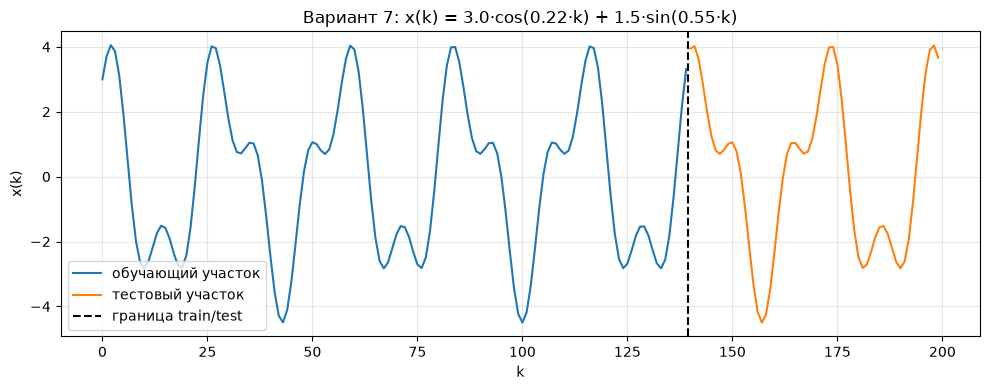

In [12]:
series = generate_series()
x_min = float(np.min(series[:TRAIN_END]))
x_max = float(np.max(series[:TRAIN_END]))
series_n = normalize(series, x_min, x_max)

print(f"Ряд: {len(series)} точек, min={series.min():.4f}, max={series.max():.4f}, "
      f"размах={series.max() - series.min():.4f}")
print(f"Нормализация по train: x_min={x_min:.4f}, x_max={x_max:.4f}")
print("x_norm = (x - x_min)/(x_max - x_min);   x = x_norm*(x_max - x_min) + x_min")

test_n = series_n[TRAIN_END:]
n_out = int(np.sum((test_n < 0) | (test_n > 1)))
print(f"Тест в норм. шкале: [{test_n.min():.4f}; {test_n.max():.4f}], вне [0; 1]: {n_out}/{len(test_n)}")
print("min/max нельзя брать по всему ряду: иначе в нормализацию «утекает» тест, "
      "и оценка обобщения становится смещённой.")

crosses_zero = bool(np.any(series[:-1] * series[1:] < 0) or np.any(np.abs(series) < 1e-6))
print(f"Ряд проходит через ноль: {'да → вместо MAPE используем sMAPE' if crosses_zero else 'нет'}")

X_all, y_all, k_all = make_windows(series_n, P_VAR)
tr = k_all < TRAIN_END
te = k_all >= TRAIN_END
X_tr, y_tr, k_tr = X_all[tr], y_all[tr], k_all[tr]
X_te, y_te, k_te = X_all[te], y_all[te], k_all[te]
print(f"Окно p={P_VAR}: обучающих примеров = {len(y_tr)} (цели k={P_VAR}..{TRAIN_END - 1}), "
      f"тестовых = {len(y_te)} (цели k={TRAIN_END}..{K_TOTAL - 1})")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(np.arange(TRAIN_END), series[:TRAIN_END], label="обучающий участок")
ax.plot(np.arange(TRAIN_END, K_TOTAL), series[TRAIN_END:], label="тестовый участок")
ax.axvline(TRAIN_END - 0.5, color="k", ls="--", label="граница train/test")
ax.set_xlabel("k")
ax.set_ylabel("x(k)")
ax.set_title(f"Вариант {VARIANT}: x(k) = {A}·cos({B}·k) + {C}·sin({D}·k)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
_save_and_show(fig, "01_series.png")

## Базовый эксперимент: $p$ и $N$ из варианта


In [13]:
print(f"Базовый запуск: p={P_VAR}, N={N_VAR}, seed={SEEDS[0]}, alpha={ALPHA}")
base = train_one(X_tr, y_tr, P_VAR, N_VAR, SEEDS[0], verbose=True)
pred_tr, true_tr, m_tr = evaluate_split(base["model"], X_tr, y_tr, x_min, x_max)
pred_te, true_te, m_te = evaluate_split(base["model"], X_te, y_te, x_min, x_max)

print(f"Эпох: {base['epochs']}, сошлось: {base['converged']}, Es = {base['Es']:.6e}")
print(f"Train  MAE={m_tr['MAE']:.4f}  RMSE={m_tr['RMSE']:.4f}  sMAPE={m_tr['sMAPE']:.2f}%")
print(f"Test   MAE={m_te['MAE']:.4f}  RMSE={m_te['RMSE']:.4f}  sMAPE={m_te['sMAPE']:.2f}%")

Базовый запуск: p=8, N=6, seed=42, alpha=0.1
Epoch     0 | Es = 6.674413e-02
Достигнут критерий остановки: 9.381300e-05 <= 0.0001
Эпох: 185, сошлось: True, Es = 9.381300e-05
Train  MAE=0.0702  RMSE=0.0828  sMAPE=8.54%
Test   MAE=0.0692  RMSE=0.0816  sMAPE=8.17%


## Исследование размера окна $p$ и числа скрытых нейронов $N$

По 5 запусков с разными seed. Фиксируем $N=N_{вар}$ при переборе $p$ и $p=p_{вар}$ при переборе $N$.


In [14]:
def run_study(p_list, n_list, title, key):
    print(title)
    header = (f"{key:>4} | {'эпохи ср.±ст.':>16} | {'test MAE ср.±ст.':>18} | "
              f"{'train MAE':>10} | {'не сошлось':>10}")
    print(header)
    print("-" * len(header))
    all_results = []
    for p, n in zip(p_list, n_list):
        Xp, yp, kp = make_windows(series_n, p)
        Xtr, ytr = Xp[kp < TRAIN_END], yp[kp < TRAIN_END]
        Xte, yte = Xp[kp >= TRAIN_END], yp[kp >= TRAIN_END]
        runs = []
        for seed in SEEDS:
            r = train_one(Xtr, ytr, p, n, seed)
            _, _, mtr = evaluate_split(r["model"], Xtr, ytr, x_min, x_max)
            _, _, mte = evaluate_split(r["model"], Xte, yte, x_min, x_max)
            r["train"], r["test"] = mtr, mte
            r["Xtr"], r["ytr"], r["Xte"], r["yte"] = Xtr, ytr, Xte, yte
            runs.append(r)
            print(f"    {key}={p if key == 'p' else n}, seed={seed}: "
                  f"эпох={r['epochs']}, Es={r['Es']:.3e}, "
                  f"testMAE={mte['MAE']:.4f}, сошлось={r['converged']}")
        ep = np.array([r["epochs"] for r in runs], dtype=float)
        te = np.array([r["test"]["MAE"] for r in runs])
        tr = np.array([r["train"]["MAE"] for r in runs])
        n_fail = sum(not r["converged"] for r in runs)
        print(f"{(p if key == 'p' else n):>4} | {ep.mean():8.1f}±{ep.std(ddof=1):<6.1f} | "
              f"{te.mean():9.4f}±{te.std(ddof=1):<7.4f} | {tr.mean():10.4f} | "
              f"{n_fail:>4}/{len(runs)}")
        all_results.append(runs)
    return all_results


P_LIST = [2, 4, P_VAR, 2 * P_VAR]
N_LIST = [1, 2, N_VAR, 2 * N_VAR]

p_study = run_study(P_LIST, [N_VAR] * len(P_LIST),
                    f"\nИсследование окна (N={N_VAR})", "p")
n_study = run_study([P_VAR] * len(N_LIST), N_LIST,
                    f"\nИсследование скрытого слоя (p={P_VAR})", "N")


Исследование окна (N=6)
   p |    эпохи ср.±ст. |   test MAE ср.±ст. |  train MAE | не сошлось
----------------------------------------------------------------------
    p=2, seed=42: эпох=20000, Es=6.253e-04, testMAE=0.1793, сошлось=False
    p=2, seed=7: эпох=20000, Es=6.261e-04, testMAE=0.1747, сошлось=False
    p=2, seed=13: эпох=20000, Es=6.260e-04, testMAE=0.1762, сошлось=False
    p=2, seed=21: эпох=20000, Es=6.478e-04, testMAE=0.1774, сошлось=False
    p=2, seed=99: эпох=20000, Es=6.249e-04, testMAE=0.1784, сошлось=False
   2 |  20000.0±0.0    |    0.1772±0.0018  |     0.1817 |    5/5
    p=4, seed=42: эпох=9281, Es=9.956e-05, testMAE=0.0673, сошлось=True
    p=4, seed=7: эпох=8562, Es=9.971e-05, testMAE=0.0673, сошлось=True
    p=4, seed=13: эпох=8305, Es=9.945e-05, testMAE=0.0676, сошлось=True
    p=4, seed=21: эпох=7301, Es=9.981e-05, testMAE=0.0661, сошлось=True
    p=4, seed=99: эпох=9019, Es=9.905e-05, testMAE=0.0661, сошлось=True
   4 |   8493.6±767.9  |    0.0669±0.000

## Многошаговый (рекурсивный) прогноз


In [15]:
def best_by_test_mae(studies, keys):
    best, best_mae = None, np.inf
    for key, runs_list in zip(keys, studies):
        for runs in runs_list:
            for r in runs:
                if r["test"]["MAE"] < best_mae:
                    best, best_mae = r, r["test"]["MAE"]
    return best


best = best_by_test_mae([p_study, n_study], ["p", "N"])
print(f"Лучшая конфигурация по test MAE: p={best['p']}, N={best['N']}, "
      f"seed={best['seed']}, MAE={best['test']['MAE']:.4f}")

# если лучшая — не базовая, обучаем её на полном критерии; иначе берём base
if best["p"] == P_VAR and best["N"] == N_VAR and best["seed"] == SEEDS[0]:
    rec_model, rec_p = base["model"], P_VAR
else:
    Xp, yp, kp = make_windows(series_n, best["p"])
    rec = train_one(Xp[kp < TRAIN_END], yp[kp < TRAIN_END],
                    best["p"], best["N"], best["seed"], verbose=True)
    rec_model, rec_p = rec["model"], best["p"]

rec_n = recursive_forecast(rec_model, series_n, rec_p, TRAIN_END, HORIZON)
rec_hat = denormalize(rec_n, x_min, x_max)
rec_true = series[TRAIN_END:TRAIN_END + HORIZON]
rec_abs = np.abs(rec_true - rec_hat)
span = float(series.max() - series.min())
thr = 0.05 * span
over = np.where(rec_abs > thr)[0]
print(f"Размах ряда = {span:.4f}, порог 5% = {thr:.4f}")
if len(over):
    print(f"Ошибка превысила 5% размаха на шаге {over[0] + 1} "
          f"(k={TRAIN_END + over[0]}, |e|={rec_abs[over[0]]:.4f})")
else:
    print(f"За {HORIZON} шагов ошибка не превысила 5% размаха "
          f"(макс. |e|={rec_abs.max():.4f} на шаге {rec_abs.argmax() + 1})")

Лучшая конфигурация по test MAE: p=16, N=6, seed=21, MAE=0.0542
Epoch     0 | Es = 4.478375e-02
Достигнут критерий остановки: 7.964417e-05 <= 0.0001
Размах ряда = 8.5506, порог 5% = 0.4275
За 30 шагов ошибка не превысила 5% размаха (макс. |e|=0.3082 на шаге 18)


## Графики


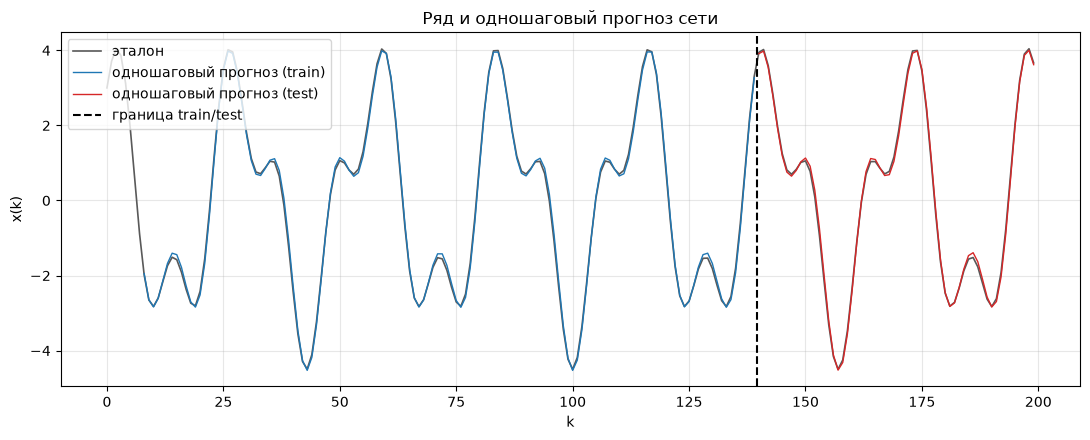

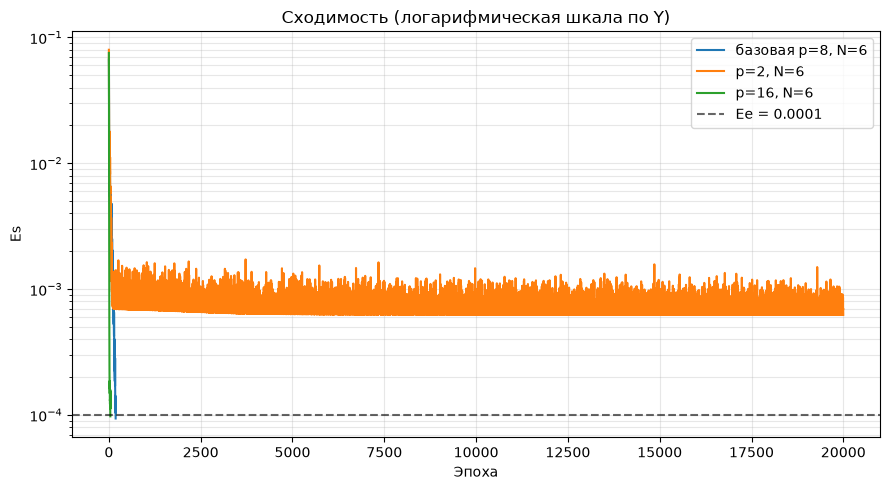

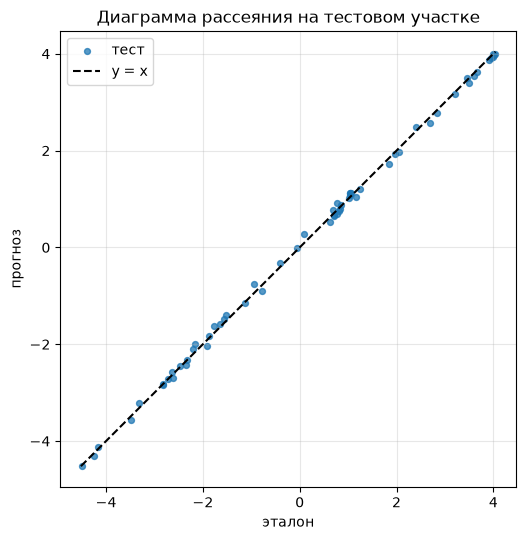

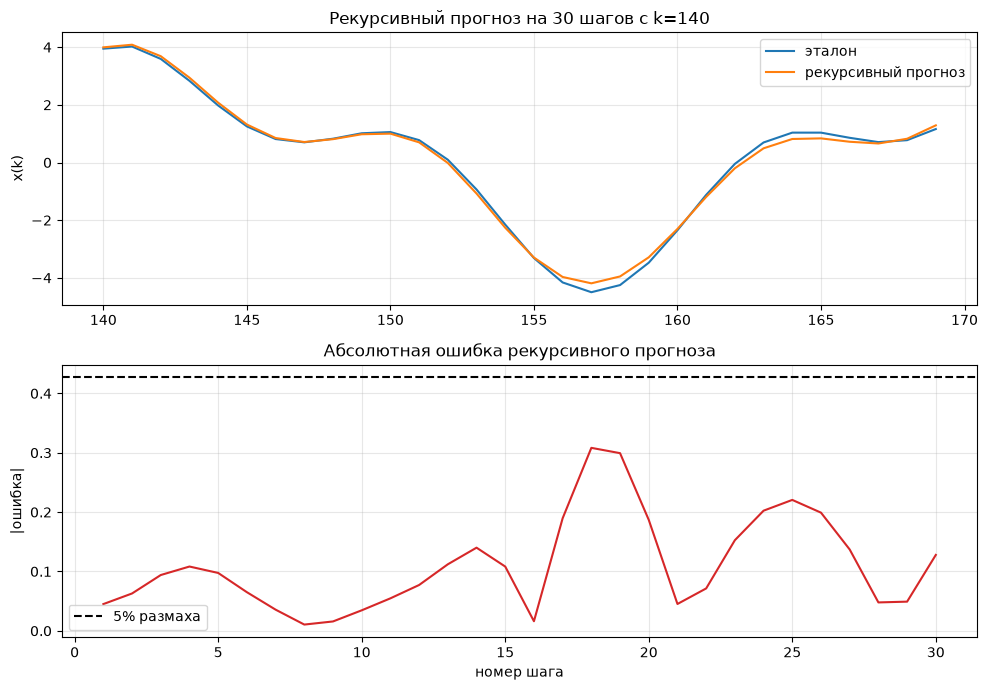

In [16]:
# одношаговый прогноз на всём ряде
one_step = np.full(K_TOTAL, np.nan)
one_step[k_tr] = pred_tr
one_step[k_te] = pred_te

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(series, color="0.35", lw=1.2, label="эталон")
ax.plot(k_tr, pred_tr, color="tab:blue", lw=1.0, label="одношаговый прогноз (train)")
ax.plot(k_te, pred_te, color="tab:red", lw=1.0, label="одношаговый прогноз (test)")
ax.axvline(TRAIN_END - 0.5, color="k", ls="--", label="граница train/test")
ax.set_xlabel("k")
ax.set_ylabel("x(k)")
ax.set_title("Ряд и одношаговый прогноз сети")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
_save_and_show(fig, "02_onestep.png")

# сходимость: база и два окна
hist_p2 = p_study[0][0]["history"]
hist_p2p = p_study[-1][0]["history"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.semilogy(base["history"], label=f"базовая p={P_VAR}, N={N_VAR}")
ax.semilogy(hist_p2, label=f"p=2, N={N_VAR}")
ax.semilogy(hist_p2p, label=f"p={2 * P_VAR}, N={N_VAR}")
ax.axhline(EE, color="k", ls="--", alpha=0.6, label=f"Ee = {EE}")
ax.set_xlabel("Эпоха")
ax.set_ylabel("Es")
ax.set_title("Сходимость (логарифмическая шкала по Y)")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
_save_and_show(fig, "03_convergence.png")

# рассеяние на тесте
fig, ax = plt.subplots(figsize=(5.5, 5.5))
lo = min(true_te.min(), pred_te.min())
hi = max(true_te.max(), pred_te.max())
ax.scatter(true_te, pred_te, s=18, alpha=0.75, label="тест")
ax.plot([lo, hi], [lo, hi], "k--", label="y = x")
ax.set_xlabel("эталон")
ax.set_ylabel("прогноз")
ax.set_title("Диаграмма рассеяния на тестовом участке")
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
_save_and_show(fig, "04_scatter.png")

# рекурсивный прогноз и рост ошибки
steps = np.arange(1, HORIZON + 1)
ks = np.arange(TRAIN_END, TRAIN_END + HORIZON)
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=False)
axes[0].plot(ks, rec_true, label="эталон")
axes[0].plot(ks, rec_hat, label="рекурсивный прогноз")
axes[0].set_ylabel("x(k)")
axes[0].set_title(f"Рекурсивный прогноз на {HORIZON} шагов с k={TRAIN_END}")
axes[0].grid(True, alpha=0.3)
axes[0].legend()
axes[1].plot(steps, rec_abs, color="tab:red")
axes[1].axhline(thr, color="k", ls="--", label="5% размаха")
axes[1].set_xlabel("номер шага")
axes[1].set_ylabel("|ошибка|")
axes[1].set_title("Абсолютная ошибка рекурсивного прогноза")
axes[1].grid(True, alpha=0.3)
axes[1].legend()
fig.tight_layout()
_save_and_show(fig, "05_recursive.png")

## Режим функционирования


In [17]:
print("3 окна из обучающего участка")
for k in (20, 70, 120):
    functioning_mode(base["model"], P_VAR, x_min, x_max, k=k, series=series, label="train")

print("3 окна из тестового участка")
for k in (145, 170, 195):
    functioning_mode(base["model"], P_VAR, x_min, x_max, k=k, series=series, label="test")

print("Пользовательские окна")
functioning_mode(
    base["model"], P_VAR, x_min, x_max,
    window=series[30:30 + P_VAR],
    label="пользовательское окно (фрагмент ряда)",
)
outlier = series[150 - P_VAR:150].copy()
outlier[P_VAR // 2] += 4.0
functioning_mode(
    base["model"], P_VAR, x_min, x_max,
    window=outlier, k=150, series=series,
    label="пользовательское окно с выбросом (+4 в середине)",
)

3 окна из обучающего участка
[train, k=20]
  окно (исх. шкала):     [-2.1631, -1.7384, -1.5121, -1.5785, -1.9104, -2.3666, -2.7365, -2.805 ]
  нормализованные входы: [0.2732, 0.3229, 0.3494, 0.3416, 0.3028, 0.2494, 0.2062, 0.1982]
  прогноз (норм. шкала): 0.2319
  прогноз (исх. шкала):  -2.5166
  истинное x(k) = -2.4220,  |ошибка| = 0.0946

[train, k=70]
  окно (исх. шкала):     [ 2.0934,  0.6824, -0.7274, -1.8803, -2.5986, -2.827 , -2.6412, -2.2191]
  нормализованные входы: [0.771 , 0.606 , 0.4412, 0.3063, 0.2223, 0.1956, 0.2173, 0.2667]
  прогноз (норм. шкала): 0.3245
  прогноз (исх. шкала):  -1.7249
  истинное x(k) = -1.7819,  |ошибка| = 0.0570

[train, k=120]
  окно (исх. шкала):     [1.2285, 1.9438, 2.7986, 3.5672, 4.0136, 3.9616, 3.349 , 2.2496]
  нормализованные входы: [0.6699, 0.7535, 0.8535, 0.9434, 0.9956, 0.9895, 0.9179, 0.7893]
  прогноз (норм. шкала): 0.6382
  прогноз (исх. шкала):  0.9578
  истинное x(k) = 0.8569,  |ошибка| = 0.1009

3 окна из тестового участка
[test, k=1

(0.6584659550262077, 1.130751422082251, 1.055445547060572)

## Эксперимент с шумом

Обучение на зашумлённом train, оценка на чистом ряде — для ответа на вопрос об обобщении.


In [18]:
rng = np.random.default_rng(123)
sigma = 0.02 * (x_max - x_min)
noisy = series.copy()
noisy[:TRAIN_END] += rng.normal(0.0, sigma, size=TRAIN_END)
x_min_n = float(np.min(noisy[:TRAIN_END]))
x_max_n = float(np.max(noisy[:TRAIN_END]))
noisy_n = normalize(noisy, x_min_n, x_max_n)
clean_n = normalize(series, x_min_n, x_max_n)

print(f"Гауссов шум на train: sigma={sigma:.4f} (2% размаха train)")
print(f"{'N':>3} | {'train MAE (шум)':>16} | {'train MAE (чист.)':>17} | {'test MAE (чист.)':>16}")

for n_hid in (N_VAR, 2 * N_VAR):
    Xn, yn, kn = make_windows(noisy_n, P_VAR)
    Xc, yc, kc = make_windows(clean_n, P_VAR)
    Xtr, ytr = Xn[kn < TRAIN_END], yn[kn < TRAIN_END]
    Xtr_c, ytr_c = Xc[kc < TRAIN_END], yc[kc < TRAIN_END]
    Xte_c, yte_c = Xc[kc >= TRAIN_END], yc[kc >= TRAIN_END]
    tr_n, tr_c, te_c = [], [], []
    for seed in SEEDS:
        r = train_one(Xtr, ytr, P_VAR, n_hid, seed)
        _, _, m_own = evaluate_split(r["model"], Xtr, ytr, x_min_n, x_max_n)
        _, _, m_cl = evaluate_split(r["model"], Xtr_c, ytr_c, x_min_n, x_max_n)
        _, _, m_te = evaluate_split(r["model"], Xte_c, yte_c, x_min_n, x_max_n)
        tr_n.append(m_own["MAE"])
        tr_c.append(m_cl["MAE"])
        te_c.append(m_te["MAE"])
    print(f"{n_hid:>3} | {np.mean(tr_n):16.4f} | {np.mean(tr_c):17.4f} | {np.mean(te_c):16.4f}")

Гауссов шум на train: sigma=0.1710 (2% размаха train)
  N |  train MAE (шум) | train MAE (чист.) | test MAE (чист.)
  6 |           0.2687 |            0.1250 |           0.1252
 12 |           0.2634 |            0.1205 |           0.1210


In [19]:
V = VARIANT
eta = ALPHA
X = np.array([0.2, 0.5, 0.8])
d = 0.6
W1 = np.array([[0.05 * V, -0.2],
               [0.3, 0.05 * V],
               [-0.1, 0.4]])
b1 = np.array([0.1, -0.1])
W2 = np.array([0.5, -0.2 * V])
b2 = 0.2

s = X @ W1 + b1
h = 1.0 / (1.0 + np.exp(-s))
y = float(h @ W2 + b2)
delta_out = y - d
delta_h = delta_out * W2 * h * (1.0 - h)
W2_new = W2 - eta * delta_out * h
b2_new = b2 - eta * delta_out
W1_new = W1 - eta * np.outer(X, delta_h)
b1_new = b1 - eta * delta_h

np.set_printoptions(precision=6, suppress=True)
print(f"V={V}, eta={eta}")
print("s_hid =", s)
print("h     =", h)
print(f"y     = {y:.6f}")
print(f"E     = 0.5*(y-d)^2 = {0.5 * (y - d) ** 2:.6f}")
print(f"delta_out = {delta_out:.6f}")
print("delta_hid =", delta_h)
print("W_out new =", W2_new, " b_out new =", b2_new)
print("W_hid new =\n", W1_new)
print("b_hid new =", b1_new)

V=7, eta=0.1
s_hid = [0.24  0.355]
h     = [0.559714 0.58783 ]
y     = -0.343105
E     = 0.5*(y-d)^2 = 0.444723
delta_out = -0.943105
delta_hid = [-0.116207  0.319901]
W_out new = [ 0.552787 -1.344562]  b_out new = 0.294310452924192
W_hid new =
 [[ 0.352324 -0.206398]
 [ 0.30581   0.334005]
 [-0.090703  0.374408]]
b_hid new = [ 0.111621 -0.13199 ]
